In [1]:
import os
import sys
import warnings
from pathlib import Path

# 1. Trouver automatiquement la racine du projet (dossier contenant pyproject.toml)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "pyproject.toml").exists():
    if (ROOT / "projet" / "pyproject.toml").exists():
        ROOT = ROOT / "projet"
        break
    ROOT = ROOT.parent

os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

print(f"Project root : {ROOT}")
print(f"Raw data dir : {ROOT / 'data' / 'raw'}")

# 2. Imports standards & projet
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, precision_score, recall_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from phishing import config
from phishing.data import clean, feature_groups, load_raw, load_split, save_splits, split
from phishing.evaluation import classification_metrics, plot_confusion_matrix, save_metrics
from phishing.url_text import registered_domain

warnings.filterwarnings("ignore", category=UserWarning)

URL, TARGET = config.URL_COL, config.TARGET_COL
SEED = config.RANDOM_STATE

Project root : C:\Users\eloil\OneDrive\Documents\Eloi\0. école\0. ESILV\A4 S7\Machine Learning\projet\phishing-url-detection-main
Raw data dir : C:\Users\eloil\OneDrive\Documents\Eloi\0. école\0. ESILV\A4 S7\Machine Learning\projet\phishing-url-detection-main\data\raw


In [2]:
raw = load_raw()
print(f"Raw dataset shape: {raw.shape[0]} rows, {raw.shape[1]} columns")

# Valeurs manquantes & doublons
print(f"Missing values     : {int(raw.isna().sum().sum())}")
print(f"Duplicate rows     : {int(raw.duplicated().sum())}")
print(f"Duplicate URLs     : {int(raw[URL].duplicated().sum())}")

# Types de colonnes
print("\nData types:")
print(raw.dtypes.value_counts())

# Distribution de la cible brute (gère le nom brut avant renommage par clean())
raw_target = TARGET if TARGET in raw.columns else raw.columns[-1]
print(f"\nRaw target column: '{raw_target}'")
display(
    pd.DataFrame({
        "count": raw[raw_target].value_counts(),
        "share (%)": (raw[raw_target].value_counts(normalize=True) * 100).round(2),
    })
)

Raw dataset shape: 11430 rows, 89 columns
Missing values     : 0
Duplicate rows     : 0
Duplicate URLs     : 1

Data types:
int64      74
float64    13
object      2
Name: count, dtype: int64

Raw target column: 'status'


,count,share (%)
status,,
legitimate,5715,50.0
phishing,5715,50.0


In [3]:
print("Shape :", raw.shape)
print("5 premières colonnes :", raw.columns[:5].tolist())
print("5 dernières colonnes :", raw.columns[-5:].tolist())

Shape : (11430, 89)
5 premières colonnes : ['url', 'length_url', 'length_hostname', 'ip', 'nb_dots']
5 dernières colonnes : ['web_traffic', 'dns_record', 'google_index', 'page_rank', 'status']


In [4]:
df_clean = clean(raw)
print(f"Cleaned dataset shape: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns")

# Groupes de variables et détection des colonnes constantes (variance nulle)
groups = feature_groups(list(df_clean.columns))
all_features = [c for cols in groups.values() for c in cols]
constant_cols = [c for c in all_features if df_clean[c].nunique() <= 1]
FEATURES = [c for c in all_features if c not in constant_cols]

print(f"\nCandidate features : {len(all_features)}")
print(f"Constant removed   : {len(constant_cols)} -> {constant_cols}")
print(f"Retained features  : {len(FEATURES)}")

for grp_name, cols in groups.items():
    kept = [c for c in cols if c in FEATURES]
    print(f"  - {grp_name}: {len(kept)} features")

# Contrôles d'intégrité
assert df_clean[FEATURES].isna().sum().sum() == 0, "Missing values remain!"
assert np.isfinite(df_clean[FEATURES].to_numpy()).all(), "Infinite values found!"
print("\nIntegrity checks passed (no NaN, no Inf, binary target).")

Cleaned dataset shape: 11429 rows, 89 columns

Candidate features : 87
Constant removed   : 6 -> ['nb_or', 'ratio_nullHyperlinks', 'ratio_intRedirection', 'ratio_intErrors', 'submit_email', 'sfh']
Retained features  : 81
  - url: 55 features
  - content: 19 features
  - external: 7 features

Integrity checks passed (no NaN, no Inf, binary target).


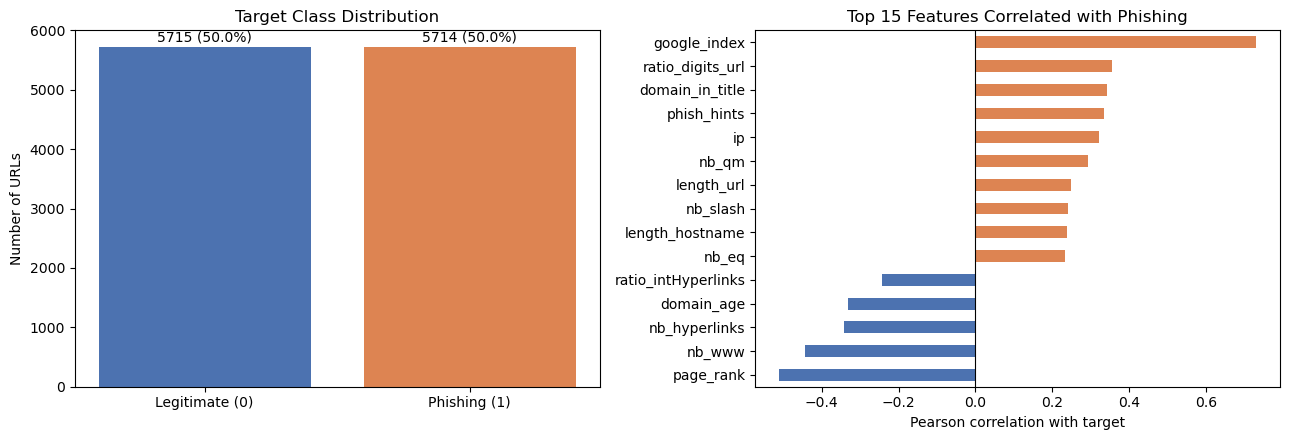

,mean,std,min,50%,max
nb_eq,0.29,1.00,0.0,0.0,19.00
length_hostname,21.09,10.78,4.0,19.0,214.00
nb_slash,4.29,1.88,2.0,4.0,33.00
length_url,61.13,55.30,12.0,47.0,1641.00
nb_qm,0.14,0.36,0.0,0.0,3.00
ip,0.15,0.36,0.0,0.0,1.00
phish_hints,0.33,0.84,0.0,0.0,10.00
domain_in_title,0.78,0.42,0.0,1.0,1.00
ratio_digits_url,0.05,0.09,0.0,0.0,0.72
google_index,0.53,0.50,0.0,1.0,1.00


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Distribution de la cible nettoyée
counts = df_clean[TARGET].value_counts().sort_index()
axes[0].bar(["Legitimate (0)", "Phishing (1)"], counts.values, color=["#4c72b0", "#dd8452"])
axes[0].set_title("Target Class Distribution")
axes[0].set_ylabel("Number of URLs")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 100, f"{v} ({v / len(df_clean):.1%})", ha="center")

# 2. Top 15 des variables les plus corrélées avec la cible
corr = df_clean[FEATURES].corrwith(df_clean[TARGET])
top_corr = corr.reindex(corr.abs().sort_values(ascending=False).head(15).index).sort_values()
colors = ["#dd8452" if v > 0 else "#4c72b0" for v in top_corr.values]
top_corr.plot.barh(ax=axes[1], color=colors)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Top 15 Features Correlated with Phishing")
axes[1].set_xlabel("Pearson correlation with target")

plt.tight_layout()
plt.show()

display(df_clean[top_corr.index[-10:]].describe().T[["mean", "std", "min", "50%", "max"]].round(2))

In [6]:
# Crée data/processed/{train,val,test}.csv s'ils n'existent pas encore
if not (config.PROCESSED_DIR / "train.csv").exists():
    save_splits(split(df_clean))

train, val, test = (load_split(name) for name in ("train", "val", "test"))

# Vérification des variables constantes uniquement sur le train (anti-leakage)
constant_train = [c for c in all_features if train[c].nunique() <= 1]
FEATURES = [c for c in all_features if c not in constant_train]

split_summary = pd.DataFrame([
    {
        "split": name,
        "n_urls": len(part),
        "share (%)": round(len(part) / len(df_clean) * 100, 1),
        "phishing_rate (%)": round(part[TARGET].mean() * 100, 2),
    }
    for name, part in [("train", train), ("val", val), ("test (locked)", test)]
])
display(split_summary)

# Diagnostic de fuite par domaine enregistré
for part in (train, val, test):
    part["domain"] = part[URL].map(registered_domain)

seen_domains = set(train["domain"])
print(f"Val URLs whose domain appears in train  : {val['domain'].isin(seen_domains).mean():.1%}")
print(f"Test URLs whose domain appears in train : {test['domain'].isin(seen_domains).mean():.1%}")

,split,n_urls,share (%),phishing_rate (%)
0,train,7999,70.0,50.01
1,val,1715,15.0,49.97
2,test (locked),1715,15.0,49.97


Val URLs whose domain appears in train  : 47.9%
Test URLs whose domain appears in train : 48.6%


In [7]:
X_train, y_train = train[FEATURES], train[TARGET].to_numpy()
X_val, y_val = val[FEATURES], val[TARGET].to_numpy()

CV_RANDOM = StratifiedKFold(n_splits=config.CV_FOLDS, shuffle=True, random_state=SEED)
CV_DOMAIN = StratifiedGroupKFold(n_splits=config.CV_FOLDS, shuffle=True, random_state=SEED)

BASELINES = {
    "Majority Class (Dummy)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression (Baseline)": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=3000, random_state=SEED),
    ),
}

def eval_metrics(y_true, proba):
    y_pred = (proba >= 0.5).astype(int)
    m = classification_metrics(y_true, y_pred, proba)
    return {
        "accuracy": m["accuracy"],
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": m["f1"],
        "fpr": m["false_positive_rate"],
        "roc_auc": m["roc_auc"],
        "brier": m["brier"],
        "log_loss": log_loss(y_true, np.clip(proba, 1e-6, 1 - 1e-6)),
    }

def cv_oof_proba(model, X, y, cv, groups=None):
    proba = np.zeros(len(y))
    for fit_idx, pred_idx in cv.split(X, y, groups):
        fitted = clone(model).fit(X.iloc[fit_idx], y[fit_idx])
        proba[pred_idx] = fitted.predict_proba(X.iloc[pred_idx])[:, 1]
    return proba

accuracy  \
model                          eval                                    
Majority Class (Dummy)         5-fold CV (random)             0.4999   
                               5-fold CV (by domain)          0.4636   
                               Validation set                 0.4997   
Logistic Regression (Baseline) 5-fold CV (random)             0.9431   
                               5-fold CV (by domain)          0.9354   
                               Validation set                 0.9534   
                               Validation (unseen domains)    0.9452   

                                                            precision  recall  \
model                          eval                                             
Majority Class (Dummy)         5-fold CV (random)              0.5000  0.8000   
                               5-fold CV (by domain)           0.4753  0.6995   
                               Validation set                  0.4997  1.0000   
Logistic Regression (Baseline) 5-fold CV (random)              0.9448  0.9412   
                               5-fold CV (by domain)           0.9419  0.9280   
                               Validation set                  0.9653  0.9405   
                               Validation (unseen domains)     0.9369  0.9110   

                                                                f1     fpr  \
model                          eval                                          
Majority Class (Dummy)         5-fold CV (random)           0.6154  0.8002   
                               5-fold CV (by domain)        0.5660  0.7724   
                               Validation set               0.6664  1.0000   
Logistic Regression (Baseline) 5-fold CV (random)           0.9430  0.0550   
                               5-fold CV (by domain)        0.9349  0.0573   
                               Validation set               0.9527  0.0338   
                               Validation (unseen domains)  0.9238  0.0352   

                                                            roc_auc   brier  \
model                          eval                                           
Majority Class (Dummy)         5-fold CV (random)            0.4999  0.5001   
                               5-fold CV (by domain)         0.4635  0.5364   
                               Validation set                0.5000  0.5003   
Logistic Regression (Baseline) 5-fold CV (random)            0.9852  0.0426   
                               5-fold CV (by domain)         0.9800  0.0497   
                               Validation set                0.9877  0.0369   
                               Validation (unseen domains)   0.9801  0.0431   

                                                            log_loss  
model                          eval                                   
Majority Class (Dummy)         5-fold CV (random)             6.9086  
                               5-fold CV (by domain)          7.4112  
                               Validation set                 6.9118  
Logistic Regression (Baseline) 5-fold CV (random)             0.1527  
                               5-fold CV (by domain)          0.1814  
                               Validation set                 0.1348  
                               Validation (unseen domains)    0.1584

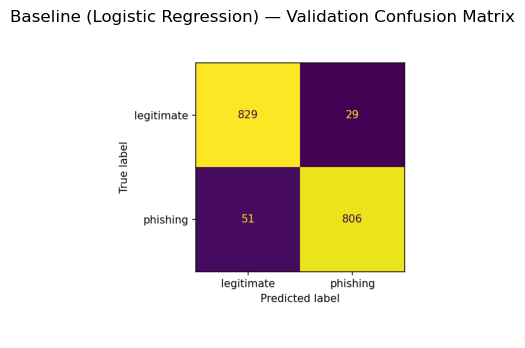

In [8]:
results = []

for name, model in BASELINES.items():
    # 1. Validation croisée stratifiée aléatoire (5 plis)
    p_cv_rand = cv_oof_proba(model, X_train, y_train, CV_RANDOM)
    results.append({"model": name, "eval": "5-fold CV (random)", **eval_metrics(y_train, p_cv_rand)})

    # 2. Validation croisée par domaine (sites inconnus)
    p_cv_dom = cv_oof_proba(model, X_train, y_train, CV_DOMAIN, groups=train["domain"])
    results.append({"model": name, "eval": "5-fold CV (by domain)", **eval_metrics(y_train, p_cv_dom)})

    # 3. Entraînement sur train, évaluation sur val
    fitted = clone(model).fit(X_train, y_train)
    p_val = fitted.predict_proba(X_val)[:, 1]
    results.append({"model": name, "eval": "Validation set", **eval_metrics(y_val, p_val)})

    if name == "Logistic Regression (Baseline)":
        unseen_val = ~val["domain"].isin(seen_domains).to_numpy()
        results.append({
            "model": name,
            "eval": "Validation (unseen domains)",
            **eval_metrics(y_val[unseen_val], p_val[unseen_val]),
        })
        baseline_val_proba = p_val

results_df = pd.DataFrame(results).set_index(["model", "eval"]).round(4)
display(results_df)

# Sauvegarde des métriques et de la matrice de confusion dans reports/
y_val_pred = (baseline_val_proba >= 0.5).astype(int)
baseline_metrics = classification_metrics(y_val, y_val_pred, baseline_val_proba)
save_metrics(baseline_metrics, config.REPORTS_DIR / "week2_baseline_val_metrics.json")

cm_path = config.FIGURES_DIR / "week2_baseline_confusion_matrix.png"
plot_confusion_matrix(y_val, y_val_pred, cm_path)

plt.figure(figsize=(5, 4))
plt.imshow(plt.imread(cm_path))
plt.axis("off")
plt.title("Baseline (Logistic Regression) — Validation Confusion Matrix")
plt.show()

## Week 2 Summary & Key Takeaways

- **Clean Dataset:** After cleaning and removing 6 constant features (`nb_or`, `ratio_nullHyperlinks`, `ratio_intRedirection`, `ratio_intErrors`, `submit_email`, `sfh`), we retain **81 numerical features** with no missing values and a balanced binary target (50% legitimate / 50% phishing).
- **Split Strategy & Domain Leakage:** Data is split 70 / 15 / 15 (`train` / `val` / `test`, stratified) and saved in `data/processed/`. Nearly half of the validation and test URLs share a registered domain with the training set. To measure true generalization to unseen websites, we evaluate models with both `StratifiedKFold` and `StratifiedGroupKFold` (grouped by domain). The test set remains locked until final evaluation.
- **Baseline Results:** Standardised **Logistic Regression** provides a strong, interpretable linear reference (~94.3% random CV accuracy, ~93.3% domain-grouped CV accuracy, ~95.3% validation accuracy), far above the 50% majority-class baseline.
- **Next Steps (Week 3):** Benchmark non-linear tree-based models (Random Forest, LightGBM, XGBoost, CatBoost), feature selection, URL lexical feature engineering, and character n-gram TF-IDF stacking.